# T4 · EDA de negocio, costo por m³ y 6 KPI

E1 · Diagnóstico del caso Aguas Andinas. Datos sintéticos docentes; no representan operaciones reales.
Ejecutar desde `E1/` (usa `T4_eda.py`, `T2_reglas.py` y `comun.py`). Período de KPI y ranking: **ago–dic 2025 UTC**.
Cada análisis declara su población y sus exclusiones. Nada se imputa.

In [1]:
import comun
comun.verificar_hashes()
import T4_eda as t4

df, ctx, ev = t4.preparar()
print(f"{len(df):,} filas físicas; {int(df['valida'].sum()):,} lecturas válidas (ene–dic); "
      f"{int(df['ago_dic'].sum()):,} válidas en ago–dic; {int((df['ago_dic'] & df['vol_ok']).sum()):,} con volumen válido en ago–dic")

253,404 filas físicas; 251,682 lecturas válidas (ene–dic); 99,500 válidas en ago–dic; 96,050 con volumen válido en ago–dic


## Exclusiones declaradas

Referencia igual a T2 (`sesgo_kpi`): lecturas válidas, volúmenes en m³ con unidad conocida, entrada ≥ 0 y salida ≤ entrada.
Cada concepto cuenta filas sobre el total de lecturas válidas de su población.

In [2]:
t4.exclusiones(df)

,poblacion,concepto,n,denominador,pct
0,ene–dic 2025,Lecturas válidas (denominador),251682,251682,100.000
1,ene–dic 2025,Volumen de entrada no convertible (unidad desc...,250,251682,0.099
2,ene–dic 2025,Volumen de entrada nulo o PENDIENTE (unidad co...,3976,251682,1.580
3,ene–dic 2025,Volumen de salida no convertible,0,251682,0.000
4,ene–dic 2025,Volumen de entrada negativo,1010,251682,0.401
5,ene–dic 2025,Salida mayor que entrada,350,251682,0.139
6,ene–dic 2025,Minutos de interrupción fuera de 0–60,350,251682,0.139
7,ene–dic 2025,Lecturas que entran a vol_ok (volúmenes),246096,251682,97.781
8,ago–dic 2025,Lecturas válidas (denominador),99500,99500,100.000
9,ago–dic 2025,Volumen de entrada no convertible (unidad desc...,250,99500,0.251


**Lectura:** en ago–dic, 3.450 de 99.500 lecturas válidas (3,5%) quedan fuera de los análisis de volumen, KPI-02 a KPI-04:
2.450 con volumen nulo o `PENDIENTE`, 250 con unidad `unidad?` (no se convierte), 400 con entrada negativa y 350 con salida mayor que entrada.
Los 350 minutos fuera de 0–60 se excluyen solo del análisis de interrupciones.

**Cero ≠ nulo:** en las horas válidas no hay minutos nulos. Un 0 es "sin interrupción medida" (95,7% de las horas válidas en ene–dic).
Las horas sin lectura (10.660 en ago–dic) no están en la tabla de hechos: se informan con la cobertura de T3, no como 0.

**Efecto de cada tratamiento** (`T2_reglas.sesgo_kpi`, ene–dic, total de red; la referencia de diferencia de volúmenes es 16,1%, no el 18,2% de ago–dic):

In [3]:
import T2_reglas as rq
sesgo = rq.sesgo_kpi(df, ev, ctx)
sesgo[sesgo["alcance"].eq("total")][["kpi", "escenario", "valor", "referencia", "delta_relativo_pct"]].round(3)

,kpi,escenario,valor,referencia,delta_relativo_pct
0,diferencia_volumenes_pct,Referencia (tratamiento correcto),16.104,16.104,0.00
1,kwh_por_m3,Referencia (tratamiento correcto),0.265,0.265,0.00
2,continuidad_simple_pct,Referencia (tratamiento correcto),98.393,98.393,0.00
3,diferencia_volumenes_pct,Sin convertir litros a m3,16.360,16.104,1.59
4,kwh_por_m3,Sin convertir litros a m3,0.002,0.265,-99.42
5,continuidad_simple_pct,Sin convertir litros a m3,98.393,98.393,0.00
6,diferencia_volumenes_pct,Sin deduplicar copias exactas,16.100,16.104,-0.03
7,kwh_por_m3,Sin deduplicar copias exactas,0.265,0.265,0.00
8,continuidad_simple_pct,Sin deduplicar copias exactas,98.394,98.393,0.00
9,diferencia_volumenes_pct,Incluyendo entrada negativa y salida > entrada,15.333,16.104,-4.79


**Lectura del efecto:** incluir entradas negativas y salidas mayores que la entrada baja la diferencia de volúmenes de 16,1% a 15,3% (−4,8% relativo).
Convertir litros mal cambia el KPI de energía por m³ en −99%. Incluir minutos > 60 baja la continuidad simple en 0,21 puntos.
Tratar horas sin lectura como 0 min sube la continuidad en 0,07 puntos: es el sesgo que la regla de cobertura evita.

## (a) Distribución

Volumen, diferencia entre entrada y salida, presión, energía e interrupciones. Las interrupciones se describen por frecuencia,
porque casi todas las horas tienen 0 minutos.

In [4]:
t4.distribucion(df).round(2)

,variable,n,media,mediana,p25,p75,ric,min,max
0,volumen_entrada_m3 (m3 por hora),246096,603.96,592.66,318.59,839.75,521.16,155.68,1390.09
1,diferencia entrada − salida (m3 por hora),246096,97.26,81.07,47.01,133.82,86.80,5.94,444.89
2,presion_bar,251682,3.77,3.79,3.58,3.99,0.42,1.10,5.31
3,energia_kwh (por hora),251682,160.21,159.29,86.63,222.14,135.52,34.50,376.32
4,minutos_interrupcion (solo horas con 0–60),251332,0.96,0.00,0.00,0.00,0.00,0.00,60.00


In [5]:
t4.proporcion_interrupcion(df)

{'n': 251332,
 'sin_interrupcion': 240530,
 'con_interrupcion': 10802,
 'pct_con_interrupcion': np.float64(4.2979007846195465),
 'mediana_si_hay': np.float64(19.0),
 'p90_si_hay': np.float64(48.0)}

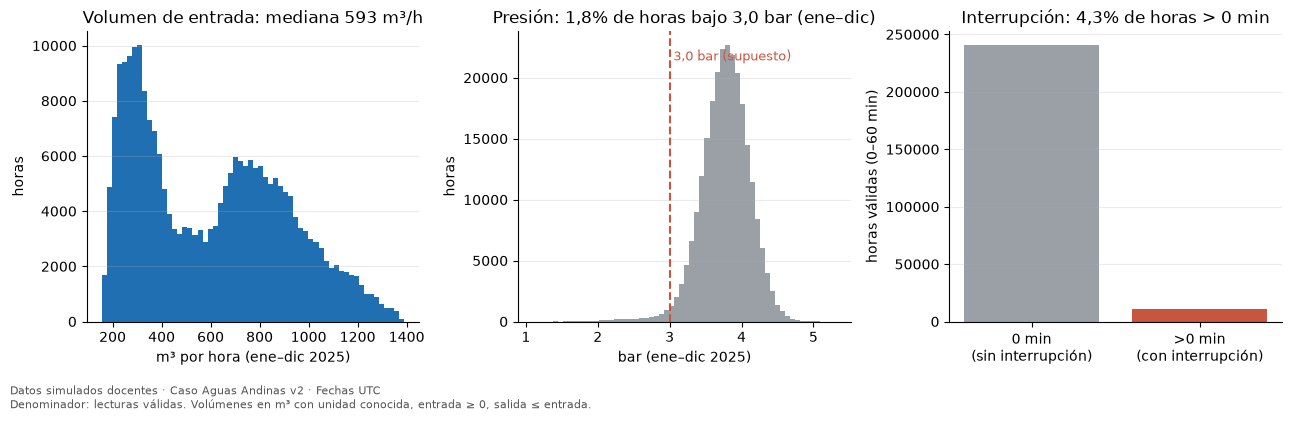

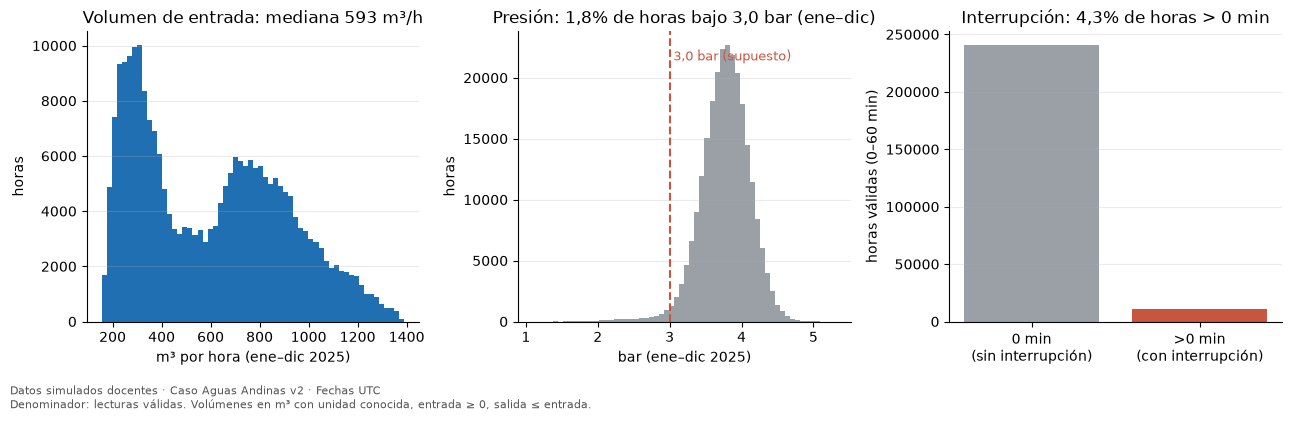

In [6]:
fig_a = t4.fig_a_distribucion(df)
fig_a

**Observación:** la mediana de entrada es 593 m³/h (P25–P75: 319–840; n = 246.096 horas con volumen válido, ene–dic).
La distribución tiene dos modos (cerca de 300 y de 750 m³/h). La presión mediana es 3,79 bar.
Solo 4,3% de las horas válidas (10.802 de 251.332) tiene interrupción; cuando la hay, la mediana es 19 min y el P90 es 48 min.

**Hipótesis:** las interrupciones son puntuales, no un estado permanente de los sectores.

**Decisión:** en el EDA y en KPI-05, medir la interrupción como **frecuencia de horas**, no como promedio de minutos (el promedio de 0,96 min/h mezcla 96% de ceros con una cola).

**Limitación:** el modo de dos picos puede mezclar sectores de escala distinta; esta figura no compara sectores.

## (b) Categorías: modo de operación y unidad por lote

Modo tras normalizar espacios y mayúsculas. Unidad sin convertir, para mostrar dónde aparecen litros.

In [7]:
t4.categorias(df)

,variable,lote,categoria,proporcion
0,modo_operacion (normalizado),actualizacion,normal,0.97562
1,modo_operacion (normalizado),actualizacion,mantenimiento,0.02438
2,modo_operacion (normalizado),ampliacion,normal,0.97513
3,modo_operacion (normalizado),ampliacion,mantenimiento,0.02487
4,modo_operacion (normalizado),base,normal,0.97532
5,modo_operacion (normalizado),base,mantenimiento,0.02468
6,unidad_volumen (crudo),actualizacion,m3,0.83327
7,unidad_volumen (crudo),actualizacion,L,0.16673
8,unidad_volumen (crudo),ampliacion,m3,0.75205
9,unidad_volumen (crudo),ampliacion,L,0.24545


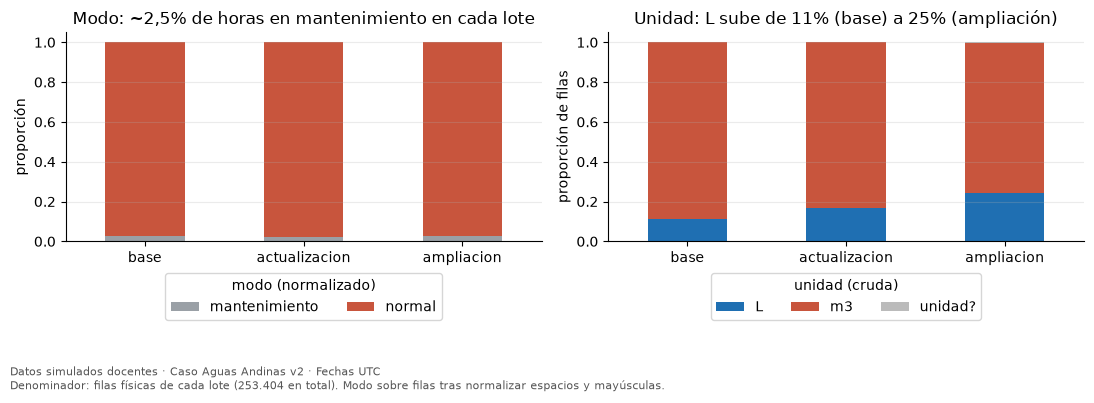

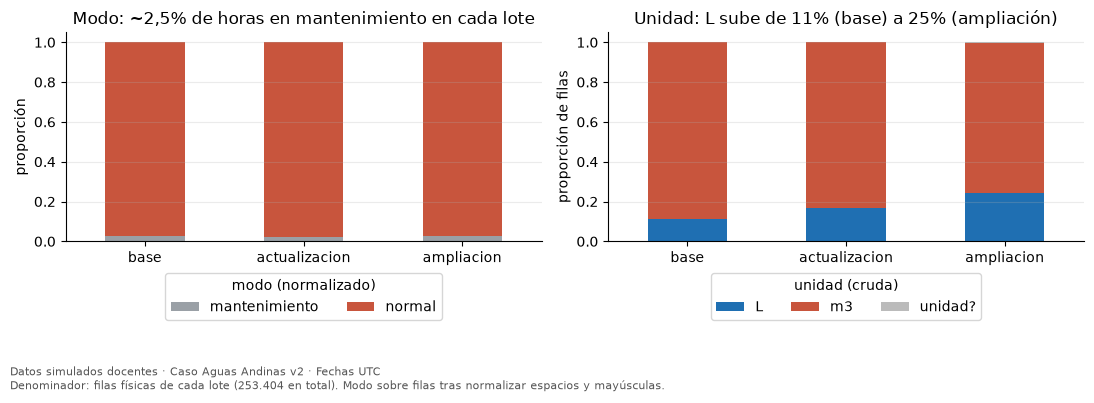

In [8]:
fig_b = t4.fig_b_categorias(df)
fig_b

**Observación:** el modo de mantenimiento es ~2,5% de las filas en los tres lotes. La proporción de litros crece de 11,3% (base)
a 16,7% (actualización) y 24,5% (ampliación); 250 filas `unidad?` aparecen solo en ampliación.

**Decisión:** la conversión se hace fila a fila (en `parse_exploratorio`), no por lote, porque la mezcla cambia entre lotes.

**Limitación:** la unidad de cada fila es un dato de origen; no se puede inferir a partir del valor del volumen.

## (c) Evolución temporal (semanal, lunes–domingo UTC)

Cada serie usa su propio denominador: kWh/m³ sobre lecturas con volumen válido, interrupción y presión sobre horas válidas.

In [9]:
serie = t4.serie_semanal(df)
serie.round(4).head(3)

,semana,horas_validas,entrada_m3_media_por_hora,kwh_por_m3,pct_horas_con_interrupcion,pct_horas_presion_baja
0,2024-12-30,3591,605.6961,0.271,3.6759,1.0025
1,2025-01-06,5023,604.8853,0.271,3.3048,1.3339
2,2025-01-13,5031,606.8436,0.2709,3.0809,1.0336


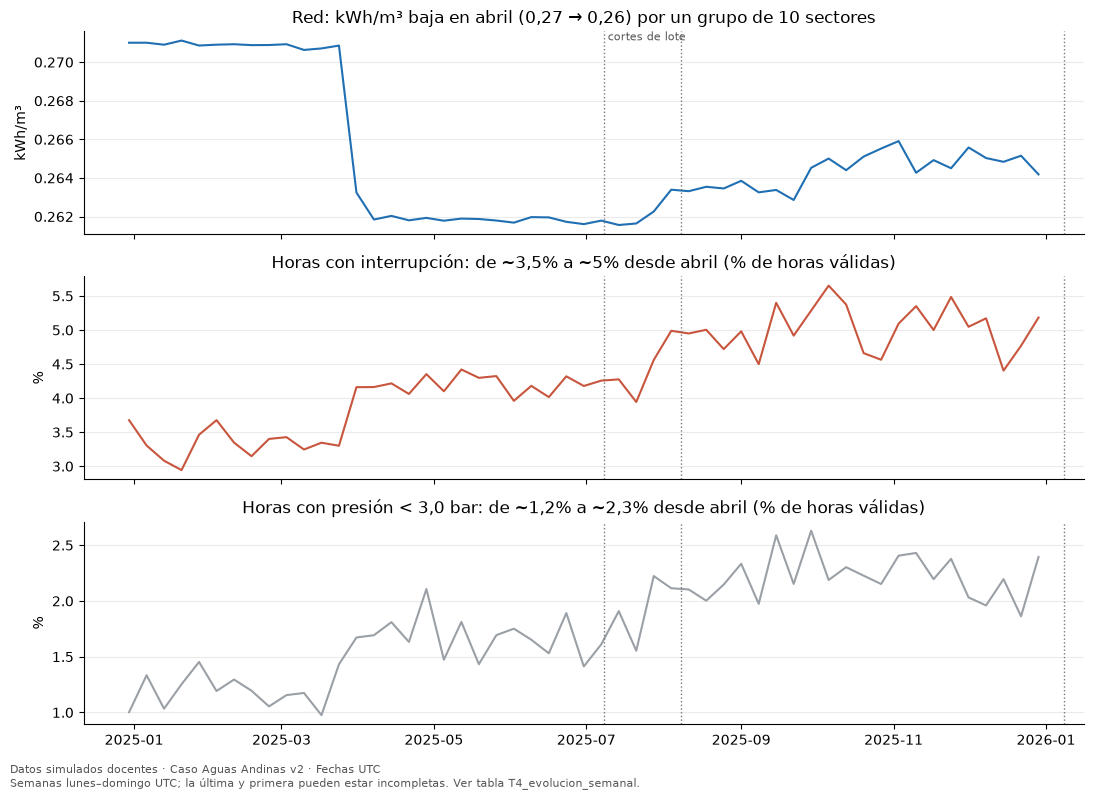

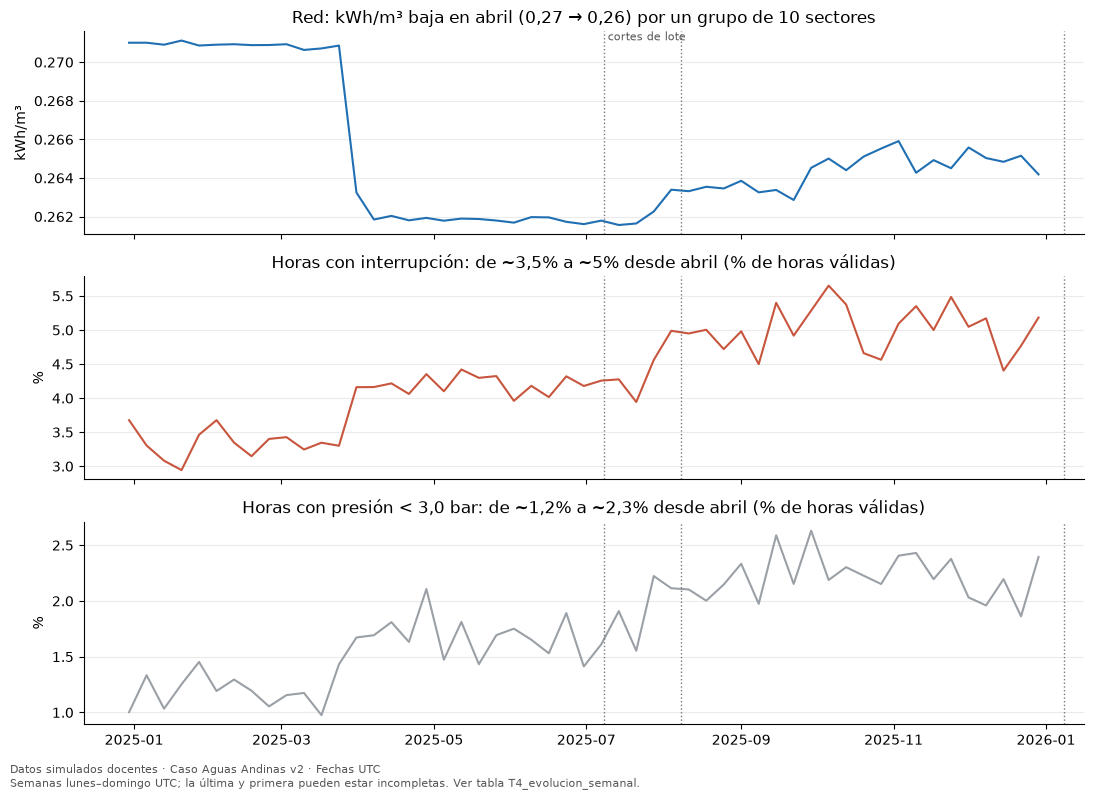

In [10]:
fig_c = t4.fig_c_evolucion(serie)
fig_c

**Observación:** en la red, kWh/m³ baja de ~0,27 a ~0,26 en abril y queda en 0,265 desde agosto. Las horas con interrupción
suben de ~3,5% a ~5% desde abril, y las horas con presión bajo 3,0 bar, de ~1,2% a ~2,3% en el mismo corte.

**Hipótesis:** el cambio de abril viene de un grupo de sectores (ver (d)). En la red agregada no aparece como cambio de operación general.

**Decisión:** tratar abril como un punto a revisar en T2 y T3 antes de atribuir la alza de interrupciones a una causa operacional.

**Limitación:** la primera y la última semana están incompletas; la red agrega 30 sectores con pesos distintos.

## (d) Comparación de segmentos

Dos cortes: sectores entre sí (ago–dic) y modo normal frente a mantenimiento (ene–dic).
Los sectores A-S20 a A-S29 se identifican aquí a partir de los datos; la lista está fijada para la figura y no es un criterio de ranking.

In [11]:
t4.comparar_segmentos(df).round(3)

,modo_operacion,horas_validas,horas_con_volumen_ok,kwh_por_m3,dif_volumen_pct,presion_mediana_bar,pct_horas_con_interrupcion,horas_con_interrupcion
0,mantenimiento,6215,6066,0.264,16.138,3.366,100.000,6206
1,normal,245467,240030,0.265,16.103,3.794,1.875,4596


In [12]:
ps = t4.por_sector(df, ctx)
ps.round(3).sort_values("dif_volumen_pct", ascending=False).head(12)

,sector_id,m3_entrada,dif_volumen_pct,kwh_por_m3,costo_clp_por_m3
21,A-S21,2322303.565,24.067,0.23,32.001
27,A-S27,2835789.145,24.065,0.227,32.209
20,A-S20,2679835.145,24.044,0.29,39.108
26,A-S26,2013581.516,24.027,0.23,31.691
22,A-S22,3410574.822,24.017,0.227,32.509
25,A-S25,1009586.982,23.980,0.304,41.043
29,A-S29,1920113.807,23.979,0.231,34.544
28,A-S28,593996.342,23.967,0.253,36.936
24,A-S24,2582347.503,23.962,0.229,34.622
23,A-S23,1076910.616,23.945,0.242,35.583


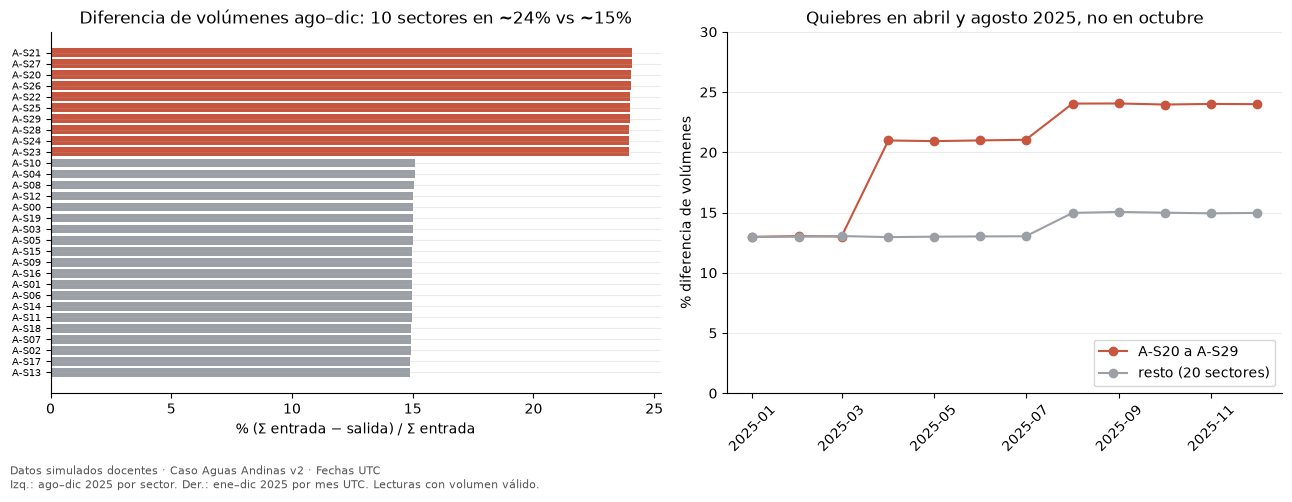

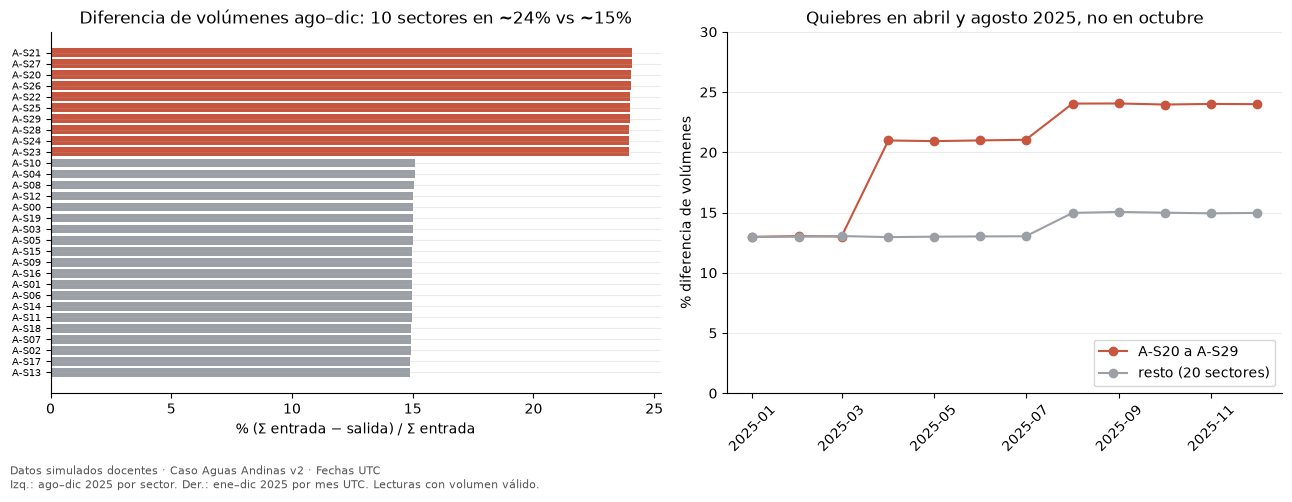

In [13]:
fig_d = t4.fig_d_segmentos(df, ps)
fig_d

**Observación (H1):** en ago–dic, 10 sectores (A-S20 a A-S29) tienen una diferencia de volúmenes de 24,0%
(29.002 lecturas con volumen válido), y los otros 20 de 15,0% (67.048 lecturas).
En el grupo, la diferencia sube de 13,0% (ene–mar) a 21,0% (abril) y a 24,0% (agosto); el resto solo sube de 13,0% a 15,0% en agosto.
En el mismo corte de abril, el grupo baja su kWh/m³ de 0,266 a 0,243 y sube sus horas con interrupción de ~3% a ~6%.

**Hipótesis:** es un cambio de medición en entrada o salida de esos sectores, o una pérdida real con menor bombeo. Con estos datos no se pueden separar.
La unidad no lo explica: en ago–dic el grupo queda en 24% y el resto en 15%, tanto en las lecturas en m³ como en las lecturas en L.

**Decisión:** en el ranking, marcar estos sectores como candidatos a inspección de **medición** (contraste de medidores de entrada y salida)
y de **operación** (bombas y válvulas), con la evidencia separada.

**Limitación:** no se atribuye fuga. Con los datos no se puede descartar un error de sensor en esos 10 sectores.

**Modo de operación:** en mantenimiento, 100% de las horas válidas con minutos en 0–60 tienen interrupción > 0; en operación normal, 1,9%.
Asociación, no causa: el modo podría registrar interrupciones planificadas, pero los datos no lo indican.

## (e) Relación bivariada

Solo variables interpretables (nunca identificadores). Asociación no es efecto.

In [14]:
t4.correlaciones(df).round(4)

,par,n,pearson,spearman
0,energia_kwh vs volumen_entrada_m3,246096,0.9597,0.9681
1,presion_bar vs diferencia entrada − salida (m3),246096,-0.0181,-0.0065


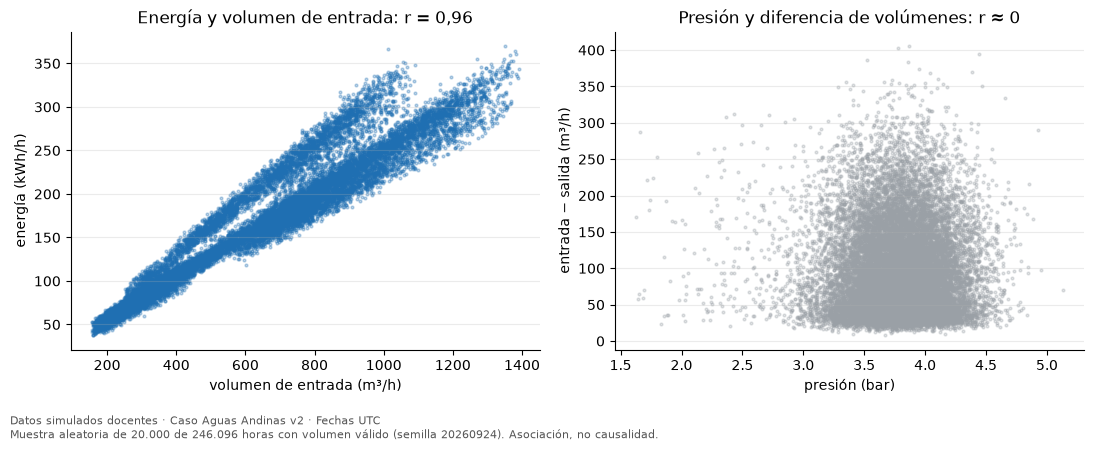

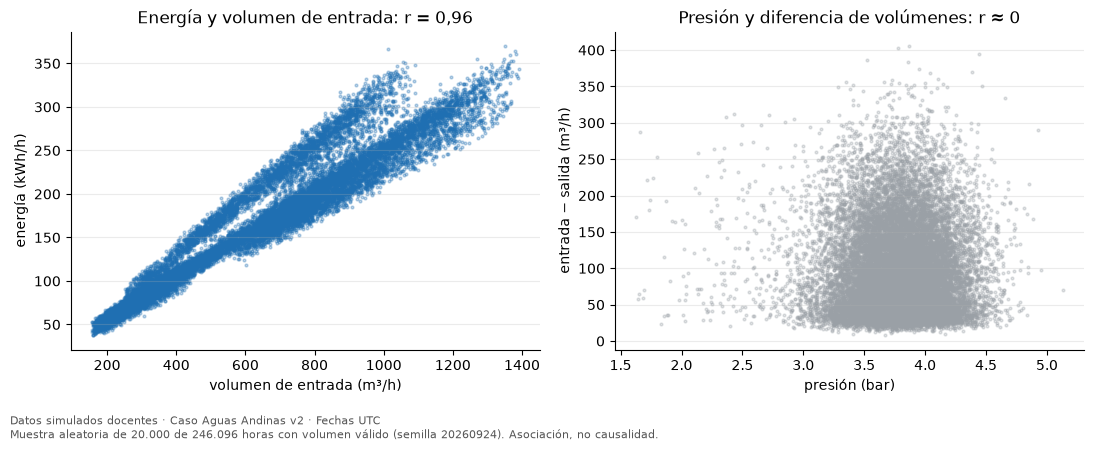

In [15]:
fig_e = t4.fig_e_bivariada(df)
fig_e

**Observación:** energía y volumen de entrada: r = 0,96 (Spearman 0,97). Presión y diferencia de volúmenes: r = −0,02.

**Hipótesis:** la alta correlación energía–volumen es esperable: el bombeo crece con el agua movida. No es evidencia de eficiencia.
La presión no explica la diferencia de volúmenes en este escenario.

**Decisión:** para comparar eficiencia usar kWh/m³ (KPI-03), no la energía bruta.

**Limitación:** los datos son sintéticos; una correlación no identifica causa.

## Costo de energía por m³ (P2)

Costo = `energia_kwh × tarifa_kwh_clp` (sector-mes, N:1, solo ago–dic). Se descompone el cambio de agosto a diciembre en
**energía por m³** (kWh/m³) y **tarifa** (CLP/kWh). Se compara la **razón de sumas** con el **promedio de razones horarias**.

In [16]:
costo = t4.costo_m3(df, ctx)
costo.round(3)

,bloque,clave,filas,m3_entrada,kwh,costo_clp,kwh_por_m3,tarifa_clp_kwh_ponderada,costo_clp_por_m3,costo_clp_por_m3_sin_convertir_litros,costo_clp_por_m3_promedio_razones_horarias,horas_sin_m3_positivo,delta_vs_agosto_clp_m3,efecto_energia_clp_m3,efecto_tarifa_clp_m3
0,mes,2025-08,19963.0,1.205292e+07,3.174263e+06,4.205565e+08,0.263,132.490,34.893,0.200,35.530,0.0,0.000,0.000,0.000
1,mes,2025-09,19327.0,1.166049e+07,3.070394e+06,4.221146e+08,0.263,137.479,36.200,0.208,36.882,0.0,1.308,-0.006,1.314
2,mes,2025-10,19213.0,1.151721e+07,3.051364e+06,4.345879e+08,0.265,142.424,37.734,0.126,38.382,0.0,2.841,0.209,2.632
3,mes,2025-11,18561.0,1.113496e+07,2.950708e+06,4.349648e+08,0.265,147.410,39.063,0.132,39.724,0.0,4.170,0.217,3.954
4,mes,2025-12,18986.0,1.136570e+07,3.012531e+06,4.591494e+08,0.265,152.413,40.398,0.135,41.086,0.0,5.505,0.224,5.281
5,total,ago–dic,96050.0,5.773127e+07,1.525926e+07,2.171373e+09,0.264,142.299,37.612,0.152,38.281,0.0,NaN,NaN,NaN


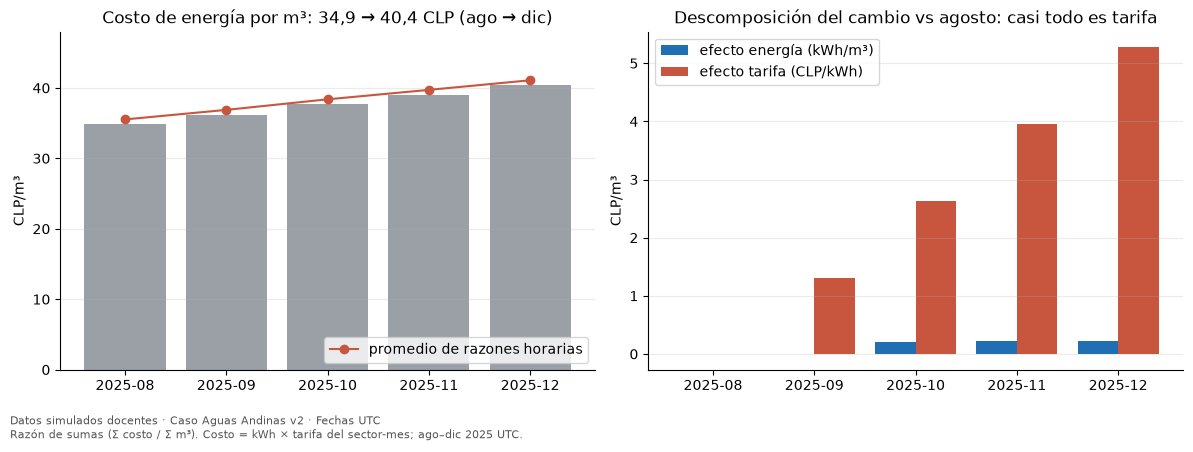

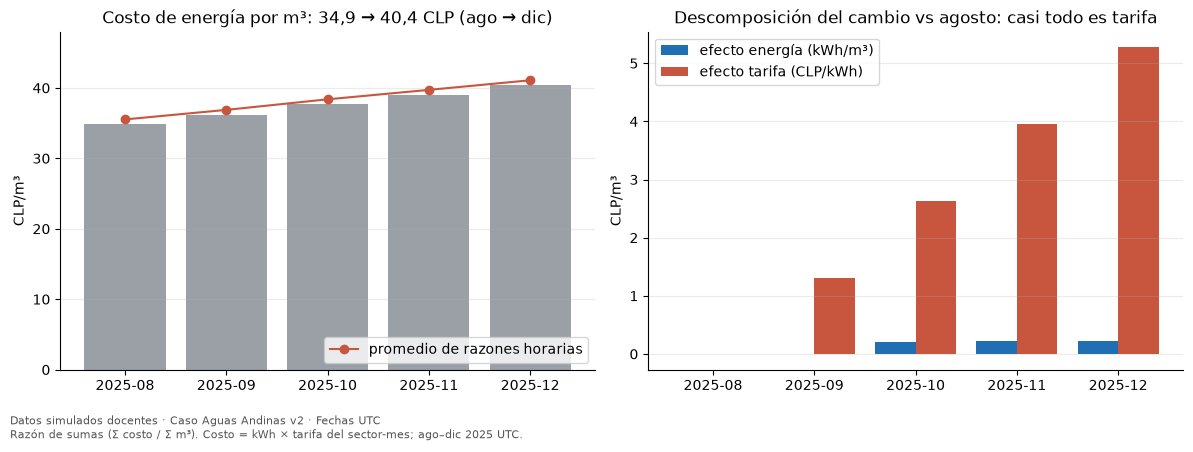

In [17]:
fig_costo = t4.fig_costo(costo)
fig_costo

**Observación (H2):** el costo de energía por m³ (razón de sumas) sube de 34,9 CLP/m³ en agosto a 40,4 en diciembre (+15,8%).
De los +5,51 CLP/m³, **5,28 (96%) son tarifa** y 0,22 (4%) energía por m³. El kWh/m³ de la red se mantiene en 0,263–0,265;
la tarifa ponderada pasa de 132 a 152 CLP/kWh.

**Unidad:** si se suman litros sin convertir, el costo aparente es 0,15 CLP/m³ (−99,6%). Es un error que el KPI no puede tolerar.

**Razón de sumas frente a promedio de razones:** 37,61 frente a 38,28 CLP/m³ (+1,8%). El KPI usa la razón de sumas (Σ costo / Σ m³),
porque el promedio de razones da el mismo peso a horas con poco volumen.

**Limitación:** la tarifa existe solo para ago–dic; antes de agosto no se trata como 0 (queda fuera de alcance).

## KPI de negocio (W6) y tabla por sector

Valores de ago–dic 2025. Las fichas siguen `plantilla_fichas_indicadores.csv`. KPI-01 se calcula en T3 (P1).

In [18]:
import pandas as pd
kpi = pd.Series(t4.kpi_valores(df, ctx), name="valor")
kpi.round(4).to_frame()

,valor
"KPI-01 continuidad (T3, sectores bajo meta con límite superior)",30.0000
KPI-02 diferencia de volúmenes (%),18.1815
KPI-03 intensidad energética (kWh/m3),0.2643
KPI-04 costo de energía (CLP/m3),37.6117
KPI-05 horas con interrupción (%),5.0156
KPI-06 horas con presión baja (%),2.2201
"KPI-06 sensibilidad 2,5 bar (%)",0.7357
"KPI-06 sensibilidad 3,5 bar (%)",18.7789
denominador KPI-02/03/04 (lecturas con volumen válido),96050.0000
"denominador KPI-05 (horas válidas con minutos en 0–60, ago–dic)",99150.0000


In [19]:
t4.fichas_kpi()[["id", "unidad", "formula", "umbral", "version_umbral"]]

,id,unidad,formula,umbral,version_umbral
0,KPI-01,%,Observada = 100 × (1 − min. interrumpidos / mi...,"99,5",v0-E1 (meta docente de metas_2025_ancho.csv)
1,KPI-02,%,100 × Σ(entrada − salida) / Σ entrada (razón d...,sin meta docente,v0-E1
2,KPI-03,kWh/m3,Σ energia_kwh / Σ volumen_entrada_m3,sin meta docente,v0-E1
3,KPI-04,CLP/m3,Σ (energia_kwh × tarifa_kwh_clp) / Σ volumen_e...,sin meta docente,v0-E1
4,KPI-05,%,100 × horas observadas con minutos_interrupcio...,sin meta docente,v0-E1
5,KPI-06,%,100 × horas observadas válidas con presion_bar...,"3,0 bar (supuesto docente; sensibilidad 2,5 y ...",v0-E1 (a validar con el profesor)


**Lectura de los KPI:**
- **KPI-01 continuidad (T3):** los 30 sectores quedan bajo la meta de 99,5% incluso en su límite superior (96,5–99,0%); la cobertura va de 76% a 93%. Lo calcula T3.
- **KPI-02 diferencia de volúmenes:** 18,2% en ago–dic (96.050 lecturas). Es mayor que el 16,1% de T2 (ene–dic); en parte por el grupo de H1.
- **KPI-03 intensidad energética:** 0,264 kWh/m³.
- **KPI-04 costo de energía:** 37,6 CLP/m³ (razón de sumas).
- **KPI-05 horas con interrupción:** 5,0% de las 99.150 horas observadas válidas.
- **KPI-06 horas con presión baja:** 2,2% bajo 3,0 bar. **Sensibilidad alta:** 0,7% con 2,5 bar y 18,8% con 3,5 bar.
  El umbral domina el resultado: no comparar este KPI sin validar el umbral con el profesor.

In [20]:
ps.round(3)

,sector_id,m3_entrada,dif_volumen_pct,kwh_por_m3,costo_clp_por_m3
0,A-S00,2836435.974,14.998,0.323,43.647
1,A-S01,3415604.485,14.955,0.254,35.306
2,A-S02,2194119.570,14.925,0.258,36.907
3,A-S03,3681640.678,14.994,0.253,37.241
4,A-S04,2353028.991,15.083,0.257,38.812
5,A-S05,1604013.203,14.991,0.33,44.565
6,A-S06,677373.400,14.954,0.284,39.456
7,A-S07,1207577.797,14.929,0.267,38.197
8,A-S08,895880.434,15.054,0.274,40.299
9,A-S09,1089455.199,14.985,0.27,40.686


## Hallazgos candidatos (formato del README)

- **H1 (sectores A-S20 a A-S29):** diferencia de volúmenes de 24% frente a 15%, con quiebre en abril y agosto de 2025. Decisión: candidatos a inspección de medición y operación.
- **H2 (costo):** +15,8% de CLP/m³ entre agosto y diciembre, casi todo por tarifa (96%). Decisión: presentar KPI-04 separando energía y tarifa.
- **H3 (interrupciones):** horas de mantenimiento con interrupción en 100% de los casos frente a 1,9% en operación normal. Decisión: separar ambos modos en KPI-05 antes de comparar sectores.

Los números están en las tablas de `salidas/tablas/T4_*.csv`.

## Productos de T4

Escribe `T4_costo_m3.csv`, `T4_fichas_kpi.csv`, `T4_por_sector.csv`, `T4_exclusiones.csv`, `T4_evolucion_semanal.csv` y las seis figuras en `salidas/`.

In [21]:
t4.ejecutar()

(            medicion_id                     fecha sector_id  volumen_entrada  \
 0       A-2025041621-16 2025-04-16 21:00:00+00:00     A-S16          207.314   
 1       A-2025020315-16 2025-02-03 15:00:00+00:00     A-S16          211.546   
 2       A-2025022723-15 2025-02-27 23:00:00+00:00     A-S15           616.26   
 3       A-2025020613-19 2025-02-06 13:00:00+00:00     A-S19            546.7   
 4       A-2025021020-19 2025-02-10 20:00:00+00:00     A-S19          399.786   
 ...                 ...                       ...       ...              ...   
 253399  A-2025080412-06 2025-08-04 12:00:00+00:00     A-S06       229171.354   
 253400  A-2025082914-20 2025-08-29 14:00:00+00:00     A-S20         1014.368   
 253401  A-2025100312-25 2025-10-03 12:00:00+00:00     A-S25           332.53   
 253402  A-2025100103-23 2025-10-01 03:00:00+00:00     A-S23          350.678   
 253403  A-2025101022-17 2025-10-10 22:00:00+00:00     A-S17          401.237   
 
         volumen_salida un